Objective

The main objective of this project is to generate a meaningful caption for an uploaded image. The model is trained using the Flickr8k dataset, which contains around 8,000 images and multiple captions for each image. In this project, OpenCV is used for image preprocessing, CNN is used for image feature extraction, and RNN/LSTM is used for generating captions word by word.

Step 1: Installing Required Libraries

In the first step, we installed all the required Python libraries in Google Colab. TensorFlow was used for building and training the deep learning model. OpenCV was used for image reading, resizing, and preprocessing. Pandas and NumPy were used for handling the dataset and numerical operations. tqdm was used to show progress while processing images, and scikit-learn was included for data handling and possible splitting.

In [1]:
#========================================
#     Step 1: Import / Install Libraries
#========================================

# This command installs all the required libraries for building the image caption generator.
# TensorFlow is used for model training, OpenCV for image processing, and Pandas/NumPy for data handling.

!pip install tensorflow opencv-python pillow numpy pandas tqdm scikit-learn

Step 2: Mounting Google Drive

Since the Flickr8k dataset was stored in Google Drive, we mounted Google Drive in Colab. This allowed Colab to access the dataset files directly from Drive. Mounting Google Drive is useful because large datasets cannot always be uploaded directly to Colab every time.

In [2]:
#========================================
#     Step 2: Mount Google Drive
#========================================
# This step connects Google Drive with Colab so we can access the dataset stored in Drive.
# It helps us use large dataset files without uploading them again and again.

from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Step 3: Extracting the Dataset

After mounting Google Drive, we extracted the Flickr8k dataset ZIP file into the Colab environment. The extracted dataset contained an image folder and a captions file. The image folder stored all the images, while the captions file contained the descriptions related to each image.

In [3]:
#========================================
#     Step 3: Extract Flickr8k Dataset
#========================================
# This step extracts the Flickr8k dataset ZIP file into the Colab environment.
# After extraction, we get the image folder and captions file required for training.

import zipfile
import os

zip_path = "/content/drive/MyDrive/ImageCaptionProject/flickr8k.zip"
extract_path = "/content/flickr8k"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")

Dataset extracted successfully!


Step 4: Checking Dataset Folders

In this step, we checked the structure of the extracted dataset. This was done to confirm the correct location of the Images folder and the captions.txt file. Checking the folders helps avoid file path errors during training.

In [4]:
#========================================
#     Step 4: Check Dataset Folders
#========================================
# This step checks the extracted dataset structure and shows the available folders and files.
# It helps us confirm the correct location of the Images folder and captions.txt file.

for root, dirs, files in os.walk("/content/flickr8k"):
    print("ROOT:", root)
    print("DIRS:", dirs[:10])
    print("FILES:", files[:10])
    print("-" * 50)



ROOT: /content/flickr8k
DIRS: ['Images']
FILES: ['captions.txt']
--------------------------------------------------
ROOT: /content/flickr8k/Images
DIRS: []
FILES: ['3275704430_a75828048f.jpg', '3319723910_af5b5f1fae.jpg', '2354064281_10afa38206.jpg', '2084157130_f288e492e4.jpg', '2251992614_0c601fae2c.jpg', '2845691057_d4ab89d889.jpg', '102351840_323e3de834.jpg', '2510560080_1439fe32f2.jpg', '1244485675_822e6efe60.jpg', '2956895529_ec6275060e.jpg']
--------------------------------------------------


Step 5: Setting Image and Caption Paths

After finding the correct dataset folders, we stored the image folder path in IMAGE_DIR and the caption file path in CAPTION_FILE. These paths were used throughout the project to read images and load captions.

In [5]:
#========================================
#     Step 5: Set Image and Caption Paths
#========================================
# This step automatically finds the Images folder and captions.txt file inside the dataset.
# These paths are stored and used later to load images and captions for training.

base_path = "/content/flickr8k"

image_dir = None
caption_file = None

for root, dirs, files in os.walk(base_path):
    if "Images" in dirs:
        image_dir = os.path.join(root, "Images")

    for file in files:
        if file.lower() == "captions.txt":
            caption_file = os.path.join(root, file)

print("Image folder:", image_dir)
print("Caption file:", caption_file)

#File Check

IMAGE_DIR = image_dir
CAPTION_FILE = caption_file

print(IMAGE_DIR)
print(CAPTION_FILE)

Image folder: /content/flickr8k/Images
Caption file: /content/flickr8k/captions.txt
/content/flickr8k/Images
/content/flickr8k/captions.txt


Step 6: Loading Captions Dataset

The captions file was loaded using Pandas. Each row in the file contained an image name and its corresponding caption. Since each image has multiple captions, the dataset provides different ways of describing the same image. These captions are later used to train the RNN/LSTM model.c

In [6]:
#========================================
#     Step 6: Load Captions Dataset
#========================================
# This step loads the captions.txt file using Pandas and displays the first few records.
# The captions are used as text data for training the RNN/LSTM caption generator.

import pandas as pd

df = pd.read_csv(CAPTION_FILE)

print(df.head())
print(df.columns)
print("Total captions:", len(df))

                       image  \
0  1000268201_693b08cb0e.jpg   
1  1000268201_693b08cb0e.jpg   
2  1000268201_693b08cb0e.jpg   
3  1000268201_693b08cb0e.jpg   
4  1000268201_693b08cb0e.jpg   

                                             caption  
0  A child in a pink dress is climbing up a set o...  
1              A girl going into a wooden building .  
2   A little girl climbing into a wooden playhouse .  
3  A little girl climbing the stairs to her playh...  
4  A little girl in a pink dress going into a woo...  
Index(['image', 'caption'], dtype='object')
Total captions: 40455


Step 7: Cleaning Captions

In this step, all captions were cleaned before training. The captions were converted to lowercase, unwanted symbols and extra spaces were removed, and special tokens startseq and endseq were added.
The startseq token tells the model where the caption starts, and the endseq token tells the model where the caption ends. This helps the LSTM generate captions in a proper sequence.

In [7]:
#========================================
#     Step 7: Clean Captions Text
#========================================
# This step cleans the caption text by converting it to lowercase and removing unwanted characters.
# startseq and endseq are added so the model can learn where each caption starts and ends.

def clean_caption(caption):
    caption = caption.lower()
    caption = ''.join(char for char in caption if char.isalpha() or char.isspace())
    caption = ' '.join(caption.split())
    return "startseq " + caption + " endseq"

df["caption"] = df["caption"].apply(clean_caption)

df.head()

,image,caption
0,1000268201_693b08cb0e.jpg,startseq a child in a pink dress is climbing u...
1,1000268201_693b08cb0e.jpg,startseq a girl going into a wooden building e...
2,1000268201_693b08cb0e.jpg,startseq a little girl climbing into a wooden ...
3,1000268201_693b08cb0e.jpg,startseq a little girl climbing the stairs to ...
4,1000268201_693b08cb0e.jpg,startseq a little girl in a pink dress going i...


Step 8: Creating Image-Caption Mapping

After cleaning the captions, we created a dictionary that maps each image to its captions. Since each image has multiple captions, this dictionary stores all captions related to one image together. This mapping is important because the model learns the relationship between image features and their corresponding text descriptions.

In [8]:
#========================================
#     Step 8: Create Image-Caption Mapping
#========================================
# This step creates a dictionary where each image name is linked with its multiple captions.
# This mapping helps the model learn the relationship between every image and its text descriptions.

captions_dict = {}

for img, caption in zip(df["image"], df["caption"]):
    if img not in captions_dict:
        captions_dict[img] = []
    captions_dict[img].append(caption)

print("Total images:", len(captions_dict))

Total images: 8091


Step 9: Extracting Image Features using OpenCV and CNN

This is one of the most important steps in the project. OpenCV was used to read each image from the dataset. Each image was converted from BGR to RGB format, resized to 224×224 pixels, and preprocessed before being passed into the CNN.

A pre-trained CNN model called VGG16 was used for feature extraction. We removed the final classification layer of VGG16 and used the second-last layer to extract meaningful image features. These features represent the important visual information present in the image, such as objects, shapes, and patterns.

In [9]:
#========================================
#     Step 9: Extract Image Features using OpenCV and CNN
#========================================
# This step uses OpenCV to read, resize, and preprocess each image from the dataset.
# A pre-trained VGG16 CNN model extracts important visual features from each image.

import cv2
import pickle
import numpy as np
from tqdm import tqdm

import tensorflow as tf
from tensorflow.keras.applications.vgg16 import VGG16, preprocess_input
from tensorflow.keras.preprocessing.image import img_to_array
from tensorflow.keras.models import Model

vgg_model = VGG16(weights="imagenet")
vgg_model = Model(inputs=vgg_model.inputs, outputs=vgg_model.layers[-2].output)

features = {}

for img_name in tqdm(captions_dict.keys()):
    img_path = os.path.join(IMAGE_DIR, img_name)

    image = cv2.imread(img_path)

    if image is None:
        continue

    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    image = cv2.resize(image, (224, 224))
    image = img_to_array(image)
    image = np.expand_dims(image, axis=0)
    image = preprocess_input(image)

    feature = vgg_model.predict(image, verbose=0)
    features[img_name] = feature

print("Extracted features:", len(features))

553467096/553467096 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step


100%|██████████| 8091/8091 [13:19<00:00, 10.12it/s]

Extracted features: 8091


Step 10: Saving Extracted Features

After extracting features from all images, we saved them into a pickle file. This was done to avoid extracting image features again and again. Feature extraction takes time, so saving the features makes the training process faster in future runs.

In [10]:
#========================================
#     Step 10: Save Extracted Image Features
#========================================
# This step saves the CNN-extracted image features into a pickle file.
# Saving features avoids repeating the time-consuming feature extraction process again.

with open("features.pkl", "wb") as f:
    pickle.dump(features, f)

print("Features saved!")

Features saved!


Step 11: Tokenizing Captions

Machine learning models cannot directly understand text. So, we used tokenization to convert words into numbers. The tokenizer assigned a unique number to every word in the captions.
For example, words like “dog”, “man”, or “playing” are converted into numeric tokens. These tokens are then used as input for the LSTM model.

In [39]:
#========================================
#     Step 11: Tokenize Captions with Limited Vocabulary
#========================================
# This step converts caption words into numerical tokens.
# We limit vocabulary size to reduce rare words and improve model learning.

from tensorflow.keras.preprocessing.text import Tokenizer

all_captions = []

for captions in captions_dict.values():
    for caption in captions:
        all_captions.append(caption)

vocab_limit = 5000

tokenizer = Tokenizer(
    num_words=vocab_limit,
    oov_token="unk"
)

tokenizer.fit_on_texts(all_captions)

vocab_size = vocab_limit
max_length = max(len(caption.split()) for caption in all_captions)

print("Vocabulary size:", vocab_size)
print("Max caption length:", max_length)
print("Total captions:", len(all_captions))

Vocabulary size: 5000
Max caption length: 37
Total captions: 40455


Step 12: Finding Vocabulary Size and Maximum Caption Length

After tokenization, we calculated the vocabulary size and the maximum caption length.
The vocabulary size represents the total number of unique words in the captions. The maximum caption length is used to make all caption sequences equal in length using padding. This is required because neural networks need fixed-size input.

In [40]:
#========================================
#     Step 12: Save Tokenizer and Max Length
#========================================
# These files are required later in Flask app also.

import pickle

with open("tokenizer.pkl", "wb") as f:
    pickle.dump(tokenizer, f)

with open("max_length.pkl", "wb") as f:
    pickle.dump(max_length, f)

print("Tokenizer and max_length saved!")

Tokenizer and max_length saved!


Step 13: Creating the Training Data Generator

A data generator was created to prepare training data in batches. For each caption, the generator creates input-output pairs.
For example, if the caption is “startseq a dog is running endseq”, the model is trained like this:

Input: startseq → Output: a
Input: startseq a → Output: dog
Input: startseq a dog → Output: is

This teaches the model to predict the next word based on the image features and the previous words. We also used padding="post" to make sure the sequence padding works correctly with the LSTM on GPU.

In [41]:
#========================================
#     Step 13: Create Training Data Generator
#========================================
# This generator creates batches of image features, partial captions, and next-word outputs.
# padding="post" is used because LSTM with mask_zero=True needs right padding.

import numpy as np
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.utils import to_categorical

def data_generator(captions_dict, features, tokenizer, max_length, vocab_size, batch_size):
    X1, X2, y = [], [], []
    n = 0

    while True:
        for img_name, captions in captions_dict.items():

            if img_name not in features:
                continue

            feature = features[img_name][0]

            for caption in captions:
                seq = tokenizer.texts_to_sequences([caption])[0]

                for i in range(1, len(seq)):
                    in_seq = seq[:i]
                    out_seq = seq[i]

                    if out_seq >= vocab_size:
                        continue

                    in_seq = pad_sequences(
                        [in_seq],
                        maxlen=max_length,
                        padding="post"
                    )[0]

                    out_seq = to_categorical(
                        [out_seq],
                        num_classes=vocab_size
                    )[0]

                    X1.append(feature)
                    X2.append(in_seq)
                    y.append(out_seq)

                    n += 1

                    if n == batch_size:
                        yield (np.array(X1), np.array(X2)), np.array(y)
                        X1, X2, y = [], [], []
                        n = 0

Step 14: Building the CNN + RNN/LSTM Model

The final model has two main inputs. The first input is the image feature extracted by the CNN. The second input is the caption sequence processed by the LSTM.

The CNN feature input passes through Dense and Dropout layers. The caption input passes through an Embedding layer and then an LSTM layer. The outputs of both parts are combined and passed through Dense layers to predict the next word in the caption.

In this model, CNN is responsible for understanding the image, while LSTM is responsible for generating the caption sequence word by word.

In [42]:
#========================================
#     Step 14: Build Improved CNN + RNN/LSTM Model
#========================================
# CNN features are used as image input.
# LSTM is used to generate captions word by word.
# BatchNormalization helps stabilize training.

from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense, Dropout, Embedding, LSTM, add, BatchNormalization
from tensorflow.keras.optimizers import Adam

# CNN image feature input
inputs1 = Input(shape=(4096,))
fe1 = Dropout(0.5)(inputs1)
fe2 = Dense(512, activation="relu")(fe1)
fe3 = BatchNormalization()(fe2)

# RNN/LSTM caption input
inputs2 = Input(shape=(max_length,))
se1 = Embedding(vocab_size, 256, mask_zero=True)(inputs2)
se2 = Dropout(0.5)(se1)
se3 = LSTM(512)(se2)

# Decoder
decoder1 = add([fe3, se3])
decoder2 = Dense(512, activation="relu")(decoder1)
decoder3 = BatchNormalization()(decoder2)
outputs = Dense(vocab_size, activation="softmax")(decoder3)

model = Model(inputs=[inputs1, inputs2], outputs=outputs)

model.compile(
    loss="categorical_crossentropy",
    optimizer=Adam(learning_rate=0.0005),
    metrics=["accuracy"]
)

model.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_3       │ (None, 4096)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer_4       │ (None, 37)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 4096)      │          0 │ input_layer_3[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_1         │ (None, 37, 256)   │  1,280,000 │ input_layer_4[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 512)       │  2,097,664 │ dropout_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 37, 256)   │          0 │ embedding_1[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_1         │ (None, 37)        │          0 │ input_layer_4[0]… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 512)       │      2,048 │ dense_3[0][0]     │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_1 (LSTM)       │ (None, 512)       │  1,574,912 │ dropout_3[0][0],  │
│                     │                   │            │ not_equal_1[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 512)       │          0 │ batch_normalizat… │
│                     │                   │            │ lstm_1[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 512)       │    262,656 │ add_1[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 512)       │      2,048 │ dense_4[0][0]     │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_5 (Dense)     │ (None, 5000)      │  2,565,000 │ batch_normalizat… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 7,784,328 (29.69 MB)

 Trainable params: 7,782,280 (29.69 MB)

 Non-trainable params: 2,048 (8.00 KB)

Step 15: Training the Model

The model was trained using the image features and caption sequences. During training, the model learns which words are likely to come next based on the image and previous words.
We first trained the model for 5 epochs to check whether the training was working properly. Later, the number of epochs can be increased to improve accuracy.

In [43]:
#========================================
#     Step 15: Train Model with Better Accuracy
#========================================
# This step trains the CNN + RNN/LSTM model.
# It displays loss, accuracy, val_loss, and val_accuracy.
# EarlyStopping stops training before overfitting.
# ModelCheckpoint saves the best model based on val_loss.

from sklearn.model_selection import train_test_split
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau

batch_size = 64
epochs = 30

image_names = list(captions_dict.keys())

train_images, val_images = train_test_split(
    image_names,
    test_size=0.2,
    random_state=42
)

train_captions_dict = {
    img: captions_dict[img]
    for img in train_images
    if img in features
}

val_captions_dict = {
    img: captions_dict[img]
    for img in val_images
    if img in features
}


def count_samples(caption_data, tokenizer):
    total = 0

    for img_name, captions in caption_data.items():
        for caption in captions:
            seq = tokenizer.texts_to_sequences([caption])[0]
            total += len(seq) - 1

    return total


train_samples = count_samples(train_captions_dict, tokenizer)
val_samples = count_samples(val_captions_dict, tokenizer)

train_steps = train_samples // batch_size
val_steps = val_samples // batch_size

print("Training images:", len(train_captions_dict))
print("Validation images:", len(val_captions_dict))
print("Training samples:", train_samples)
print("Validation samples:", val_samples)
print("Training steps per epoch:", train_steps)
print("Validation steps per epoch:", val_steps)


train_generator = data_generator(
    train_captions_dict,
    features,
    tokenizer,
    max_length,
    vocab_size,
    batch_size
)

val_generator = data_generator(
    val_captions_dict,
    features,
    tokenizer,
    max_length,
    vocab_size,
    batch_size
)


callbacks = [
    ModelCheckpoint(
        "best_image_caption_model.keras",
        monitor="val_loss",
        save_best_only=True,
        mode="min",
        verbose=1
    ),

    EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=0.00001,
        verbose=1
    )
]


history = model.fit(
    train_generator,
    epochs=epochs,
    steps_per_epoch=train_steps,
    validation_data=val_generator,
    validation_steps=val_steps,
    callbacks=callbacks,
    verbose=1
)

Training images: 6472
Validation images: 1619
Training samples: 381587
Validation samples: 95206
Training steps per epoch: 5962
Validation steps per epoch: 1487
Epoch 1/30
5960/5962 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.2436 - loss: 4.8588
Epoch 1: val_loss improved from None to 4.12353, saving model to best_image_caption_model.keras

Epoch 1: finished saving model to best_image_caption_model.keras
5962/5962 ━━━━━━━━━━━━━━━━━━━━ 134s 22ms/step - accuracy: 0.2946 - loss: 4.1223 - val_accuracy: 0.3185 - val_loss: 4.1235 - learning_rate: 5.0000e-04
Epoch 2/30
5959/5962 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.3600 - loss: 3.4122
Epoch 2: val_loss improved from 4.12353 to 3.81277, saving model to best_image_caption_model.keras

Epoch 2: finished saving model to best_image_caption_model.keras
5962/5962 ━━━━━━━━━━━━━━━━━━━━ 144s 24ms/step - accuracy: 0.3707 - loss: 3.3244 - val_accuracy: 0.3389 - val_loss: 3.8128 - learning_rate: 5.0000e-04
Epoch 3/30
5961/5962 ━━━━━━━━━━━━━

Step 16: Saving the Trained Model

After training, the model was saved so that it could be used later without training again. We saved the model in .keras format because it works better with newer versions of TensorFlow and avoids loading errors that can happen with old .h5 files.

Available history keys: dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss', 'learning_rate'])


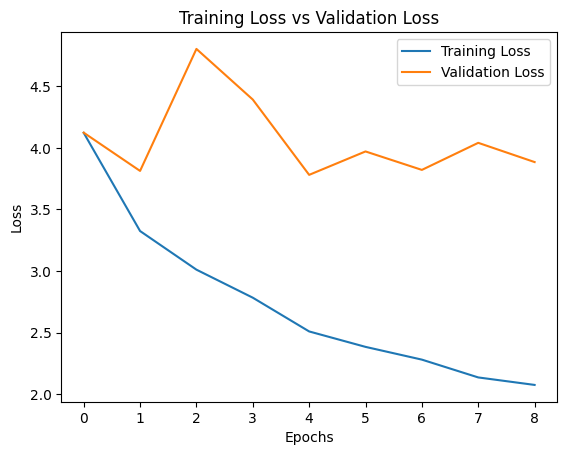

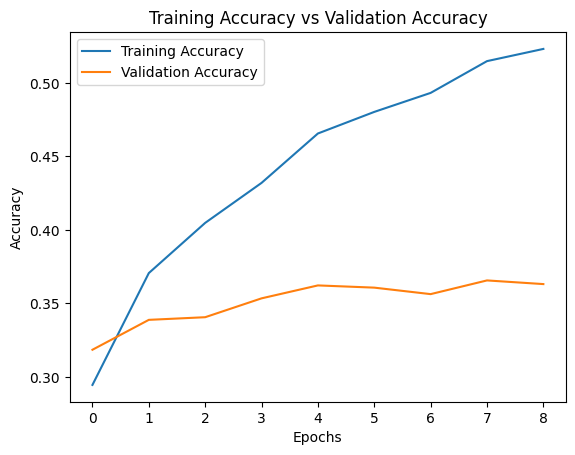

In [44]:
#========================================
#     Step 16: Plot Training and Validation Results
#========================================
# This step plots training loss, validation loss,
# training accuracy, and validation accuracy.

import matplotlib.pyplot as plt

print("Available history keys:", history.history.keys())

# Loss graph
plt.figure()
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Training Loss vs Validation Loss")
plt.legend()
plt.show()

# Accuracy graph
plt.figure()
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("Training Accuracy vs Validation Accuracy")
plt.legend()
plt.show()

In [45]:
#========================================
#     Step 16B: Save Final Trained Model
#========================================
# This saves the final restored best model.
# ModelCheckpoint also saved best_image_caption_model.keras.

model.save("image_caption_model.keras")

print("Final model saved as image_caption_model.keras")
print("Best model saved as best_image_caption_model.keras")

Final model saved as image_caption_model.keras
Best model saved as best_image_caption_model.keras


Step 17: Testing Caption Generation in Colab

After saving the model, we tested it on one image from the dataset. The image feature was passed to the trained model, and the model generated a caption word by word. The process started with startseq and continued until the model predicted endseq.

In [46]:
#========================================
#     Step 17: Test Caption Generation using Beam Search
#========================================
# Beam Search gives better captions than simple argmax.
# It checks multiple possible word sequences and selects the best caption.

import random
import numpy as np
from IPython.display import Image, display
from tensorflow.keras.preprocessing.sequence import pad_sequences


index_word = {}

for word, index in tokenizer.word_index.items():
    if index < vocab_size:
        index_word[index] = word


def generate_caption_beam_search(model, tokenizer, photo, max_length, beam_index=5):
    start = "startseq"
    sequences = [(start, 0.0)]

    for _ in range(max_length):
        all_candidates = []

        for in_text, score in sequences:
            if in_text.split()[-1] == "endseq":
                all_candidates.append((in_text, score))
                continue

            sequence = tokenizer.texts_to_sequences([in_text])[0]

            sequence = pad_sequences(
                [sequence],
                maxlen=max_length,
                padding="post"
            )

            yhat = model.predict([photo, sequence], verbose=0)[0]

            top_words = np.argsort(yhat)[-beam_index:]

            for word_id in top_words:
                word = index_word.get(word_id)

                if word is None:
                    continue

                if word in ["startseq", "unk"]:
                    continue

                new_text = in_text + " " + word
                new_score = score - np.log(yhat[word_id] + 1e-9)

                all_candidates.append((new_text, new_score))

        ordered = sorted(all_candidates, key=lambda tup: tup[1])
        sequences = ordered[:beam_index]

    final_caption = sequences[0][0]
    final_caption = final_caption.replace("startseq", "")
    final_caption = final_caption.replace("endseq", "")
    final_caption = final_caption.strip()

    return final_caption

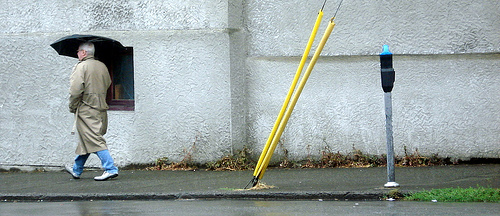

Generated Caption: a boy in a red shirt walks down the street


In [56]:
#========================================
#     Test on Random Image
#========================================

test_image_name = random.choice(list(features.keys()))
test_image_path = os.path.join(IMAGE_DIR, test_image_name)

display(Image(filename=test_image_path))

photo = features[test_image_name]

caption = generate_caption_beam_search(
    model,
    tokenizer,
    photo,
    max_length,
    beam_index=5
)

print("Generated Caption:", caption)

In [ ]:
#========================================
#     Step 18: Download Final Files
#========================================
# These files are used in VS Code Flask app.

from google.colab import files

files.download("best_image_caption_model.keras")
files.download("image_caption_model.keras")
files.download("tokenizer.pkl")
files.download("max_length.pkl")

Final Summary

The Colab part of the project was used for training the image captioning model. OpenCV was used to preprocess the images, VGG16 CNN was used to extract image features, and LSTM was used to generate captions. After training, the model and required supporting files were saved and downloaded. These files were then used in the Flask web app, where users can upload an image and get an automatically generated caption.